## Churn Analysis and Customer Intelligence

In [1]:
# Churn Analysis and Customer Intelligence

In [2]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

## 1. Import database / data  

In [ ]:


# Excel file path
excel_file = 'customer_churn_data_raw.xlsx'

# Create SQLite database connection
conn = sqlite3.connect('customer_churn.db')

# Read all sheet names from Excel file
excel_data = pd.ExcelFile(excel_file)

# Loop through each sheet and store as separate table
for sheet in excel_data.sheet_names:
    df = pd.read_excel(excel_file, sheet_name=sheet) # Read sheet into dataframe
    # Write dataframe to SQLite table
    df.to_sql(
        name=sheet,          # Table name = Sheet name
        con=conn,
        if_exists='replace', # Replace table if already exists
        index=False
    )

# Close connection
conn.close()

print("All sheets successfully converted into SQLite tables.")

All sheets successfully converted into SQLite tables.


In [4]:
# Data Import: db file to pandas, storing each table to a separate df

# Connect to SQLite database
conn = sqlite3.connect('customer_churn.db')

# sql query to Get all table names
sql_query = """
        SELECT name
        FROM sqlite_master
        WHERE type='table';
"""

# read sql query in pandas
tables = pd.read_sql(sql_query, conn)

# create dataframe for each table
for table_name in tables['name']:
    df = pd.read_sql(f"SELECT * FROM {table_name}", conn) # Read table into dataframe
    globals()[f"df_{table_name}"] = df                    # Create dynamic dataframe name
    print(f"Created dataframe: df_{table_name}")

# Close connection
conn.close()

Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


In [5]:
# Print table names and column names
conn = sqlite3.connect('customer_churn.db')

for table_name in tables['name']:
    print(f"\nTable Name: {table_name}")
    # Get column information
    columns_query = f"PRAGMA table_info({table_name});"
    columns = pd.read_sql(columns_query, conn)
    print("Columns:")
    print(columns['name'].tolist())

# Close connection
conn.close()


Table Name: db_customer
Columns:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name: db_subscription
Columns:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score', 'churn_flag']

Table Name: db_support
Columns:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


## 2. Data cleaning

In [7]:
# df_db_customer.head() # customer table
df_db_customer.tail()

,customerid,name,country,state,gender,dob,interests,pincode
4995,CUST-04996,Customer_04996,Germany,Hesse,Male,1990-11-18 00:00:00,sports,708856
4996,CUST-04997,Customer_04997,India,West Bengal,Female,2003-05-11 00:00:00,shopping,737534
4997,CUST-04998,Customer_04998,India,Uttar Pradesh,Female,1984-01-31 00:00:00,sports,308758
4998,CUST-04999,Customer_04999,Canada,Quebec,Female,2004-10-07 00:00:00,movies,758731
4999,CUST-05000,Customer_05000,USA,Florida,Female,1990-01-09 00:00:00,travel,447493


In [8]:
df_db_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  5000 non-null   object
 1   name        5000 non-null   object
 2   country     5000 non-null   object
 3   state       5000 non-null   object
 4   gender      5000 non-null   object
 5   dob         5000 non-null   object
 6   interests   5000 non-null   object
 7   pincode     5000 non-null   int64 
dtypes: int64(1), object(7)
memory usage: 312.6+ KB


In [9]:
# a. rename col - name to customer_name
# b. drop columns - interest and pincode
# c. change data type - dob
# d. data standardization - gender
# e. fix missing values (using existing data) - country

#### a. Rename Col

In [10]:
# a. rename col - name to customer_name

df_db_customer.rename(columns = {'name' : 'customer_name'}, inplace= True)

#### b. Drop columns

In [11]:
# b. drop columns - interest and pincode

# df_db_customer.drop(df_db_customer.columns[-2:], axis=1)
# df_db_customer.drop(df_db_customer.columns[6:], axis=1)

df_db_customer.drop(columns=['interests', 'pincode'], inplace=True)  # using col name

In [12]:
df_db_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerid     5000 non-null   object
 1   customer_name  5000 non-null   object
 2   country        5000 non-null   object
 3   state          5000 non-null   object
 4   gender         5000 non-null   object
 5   dob            5000 non-null   object
dtypes: object(6)
memory usage: 234.5+ KB


#### c. Change data type

In [13]:
# c. change data type - dob
# df_db_customer.drop(df_db_customer.columns[-2:], axis=1)
df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])

In [14]:
df_db_customer

,customerid,customer_name,country,state,gender,dob
0,CUST-00001,Customer_00001,India,Karnataka,Male,2002-01-25
1,CUST-00002,Customer_00002,Singapore,West Region,Female,1989-05-21
2,CUST-00003,Customer_00003,UK,Wales,Male,1987-09-04
3,CUST-00004,Customer_00004,USA,New York,Male,1969-03-14
4,CUST-00005,Customer_00005,India,Tamil Nadu,Female,1986-10-16
...,...,...,...,...,...,...
4995,CUST-04996,Customer_04996,Germany,Hesse,Male,1990-11-18
4996,CUST-04997,Customer_04997,India,West Bengal,Female,2003-05-11
4997,CUST-04998,Customer_04998,India,Uttar Pradesh,Female,1984-01-31
4998,CUST-04999,Customer_04999,Canada,Quebec,Female,2004-10-07


#### d. Data standardization

In [15]:
# d. data standardization - gender

# df_db_customer['gender'].unique()
df_db_customer['gender'] = df_db_customer['gender'].replace({'Men' : 'Male', 'Women' : 'Female'})

In [16]:
df_db_customer['gender'].unique()

array(['Male', 'Female'], dtype=object)

#### e. Fix missing values

In [17]:
# e. fix missing values - country

# df_db_customer['country'].isna().sum()
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob


In [18]:
# country and state - unique value pair

# Creating state → country map from non-null rows
state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()

# Fill the missing country using State
df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

In [19]:
df_db_customer[df_db_customer['country'].isna()] # no null value in country col

,customerid,customer_name,country,state,gender,dob


In [20]:
df_db_subscription.head() # subcription table

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,CUST-00001,2024-04-29 00:00:00,Paid,2024-07-29 00:00:00,Standard,Quarterly,None,None,18.67,495,68,0
1,CUST-00002,2022-02-03 00:00:00,Paid,2023-02-03 00:00:00,Basic,Annual,None,None,13.45,861,57,0
2,CUST-00003,2024-01-16 00:00:00,Paid,2024-02-16 00:00:00,Standard,Monthly,None,None,24.56,526,43,0
3,CUST-00004,2022-06-03 00:00:00,Referral,2023-06-03 00:00:00,Premium,Annual,2024-08-24 00:00:00,Service issue,36.08,1704,48,1
4,CUST-00005,2022-09-17 00:00:00,Referral,2023-09-17 00:00:00,Premium,Annual,None,None,43.09,2088,12,0


In [21]:
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               5000 non-null   object 
 1   subscription_start_date  5000 non-null   object 
 2   subscription_type        5000 non-null   object 
 3   renewal_date             5000 non-null   object 
 4   plan_type                5000 non-null   object 
 5   contract_type            5000 non-null   object 
 6   cancellation_date        1157 non-null   object 
 7   cancellation_reason      1157 non-null   object 
 8   monthly_charges          5000 non-null   float64
 9   cltv                     5000 non-null   int64  
 10  churn_score              5000 non-null   int64  
 11  churn_flag               5000 non-null   int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 468.9+ KB


In [22]:
# change data type to date - subscription_start_date , renewal_date, cancellation_date
date_col = ['subscription_start_date', 'renewal_date', 'cancellation_date']

df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               5000 non-null   object        
 1   subscription_start_date  5000 non-null   datetime64[ns]
 2   subscription_type        5000 non-null   object        
 3   renewal_date             5000 non-null   datetime64[ns]
 4   plan_type                5000 non-null   object        
 5   contract_type            5000 non-null   object        
 6   cancellation_date        1157 non-null   datetime64[ns]
 7   cancellation_reason      1157 non-null   object        
 8   monthly_charges          5000 non-null   float64       
 9   cltv                     5000 non-null   int64         
 10  churn_score              5000 non-null   int64         
 11  churn_flag               5000 non-null   int64         
dtypes: datetime64[ns](3), float64(1), 

In [23]:
df_db_support.head() # support table

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,CUST-00011,2022-06-13 00:00:00,N,77,None,slow response
1,CUST-00014,2025-02-11 00:00:00,N,53,None,service issue
2,CUST-00014,2025-12-31 00:00:00,N,64,None,slow response
3,CUST-00017,2025-12-31 00:00:00,N,69,None,slow response
4,CUST-00017,2025-02-10 00:00:00,N,72,None,demaned refund


In [24]:
df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2782 entries, 0 to 2781
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      2782 non-null   object
 1   complaint_date  2782 non-null   object
 2   escalations     2782 non-null   object
 3   csat_score      2782 non-null   int64 
 4   col_1           0 non-null      object
 5   comment         2782 non-null   object
dtypes: int64(1), object(5)
memory usage: 130.5+ KB


In [25]:
# drop columns
df_db_support.drop(columns=['col_1', 'comment'], inplace=True)

In [26]:
# change data type to date - complaint_date

df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])
df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2782 entries, 0 to 2781
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      2782 non-null   object        
 1   complaint_date  2782 non-null   datetime64[ns]
 2   escalations     2782 non-null   object        
 3   csat_score      2782 non-null   int64         
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 87.1+ KB


## 3. Feature Engineering & Data Analysis

#### Create a new col

In [27]:
# create a new col using existing col - churn flag

# Customer is churned if cancellation_date is not null
df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(), 1, 0)
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,CUST-00001,2024-04-29,Paid,2024-07-29,Standard,Quarterly,NaT,None,18.67,495,68,0
1,CUST-00002,2022-02-03,Paid,2023-02-03,Basic,Annual,NaT,None,13.45,861,57,0
2,CUST-00003,2024-01-16,Paid,2024-02-16,Standard,Monthly,NaT,None,24.56,526,43,0
3,CUST-00004,2022-06-03,Referral,2023-06-03,Premium,Annual,2024-08-24,Service issue,36.08,1704,48,1
4,CUST-00005,2022-09-17,Referral,2023-09-17,Premium,Annual,NaT,None,43.09,2088,12,0


#### Merge Dataframes - JOINs

In [28]:
# first fix support table duplicates then merge
# Note: while merging df's always check the shape before and after
df = (df_db_subscription
            .merge(df_db_customer, on = 'customerid', how= 'left')
            .merge(df_db_support, on = 'customerid', how= 'left') )

In [29]:
df_db_subscription.shape

(5000, 12)

In [30]:
df.shape

(6063, 20)

In [31]:
print('df_db_subscription unique value:', df_db_subscription['customerid'].nunique())
print('df_db_customer unique value:', df_db_customer['customerid'].nunique())
print('df_db_support unique value:', df_db_support['customerid'].nunique())
print('df_db_support all value:', df_db_support['customerid'].size)

df_db_subscription unique value: 5000
df_db_customer unique value: 5000
df_db_support unique value: 1719
df_db_support all value: 2782


In [32]:
df_db_support

,customerid,complaint_date,escalations,csat_score
0,CUST-00011,2022-06-13,N,77
1,CUST-00014,2025-02-11,N,53
2,CUST-00014,2025-12-31,N,64
3,CUST-00017,2025-12-31,N,69
4,CUST-00017,2025-02-10,N,72
...,...,...,...,...
2777,CUST-04996,2023-03-30,Y,61
2778,CUST-04996,2023-04-03,Y,48
2779,CUST-04998,2021-02-26,N,46
2780,CUST-04999,2025-05-21,N,73


In [33]:
df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform('count')

In [34]:
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid', keep= 'last')

In [35]:
df_db_support['customerid'].size

1719

In [36]:
# merge df
df = (df_db_subscription
            .merge(df_db_customer, on = 'customerid', how= 'left')
            .merge(df_db_support, on = 'customerid', how= 'left') )

In [37]:
df.shape

(5000, 21)

#### Export dataframe

In [38]:
# export dataframe to csv file
df.to_csv('exported_churned_data.csv', index=False)

## Data Analysis

In [39]:
# 1. Churn Rate

In [40]:
churn_rate = df['churn_flag'].mean()*100
print("Churn Rate = ", round(churn_rate,2), "%")

Churn Rate =  23.14 %


In [41]:
# 2. Retenion Rate
retention_rate = 100 - churn_rate
print("Retention Rate = ", round(retention_rate,2), "%")

Retention Rate =  76.86 %


In [42]:
# 3. Churn by Plan type
churn_by_plan = (df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct'))
print(churn_by_plan)

  plan_type  churn_rate_pct
0     Basic           23.39
1   Premium           22.92
2  Standard           23.09


In [43]:
# 4 a. Churn by state + sum(revenue) & count of users  -- home work **
# 4 b. Churn by subscription type + sum(revenue) & count of users   -- home work **

In [44]:
# 5. ARPU - Avg Revenue per user
arpu = df['monthly_charges'].mean()
print('ARPU = ', round(arpu,2))

ARPU =  25.6


In [45]:
# homework - calculate customer age

In [46]:
# 6. Avg Customer Tenure
# count of days users has used our service : cancellation date else current date
today = pd.Timestamp.today()

df['tenure_days'] = np.where(
        df['cancellation_date'].notna(),

    (df['cancellation_date'] - df['subscription_start_date']).dt.days,

    (today - df['subscription_start_date']).dt.days
)

avg_tenure = df['tenure_days'].mean()
print("Avg Tenure (Days) = ", round(avg_tenure),0)

Avg Tenure (Days) =  1263 0


In [47]:
# 7. Revenue at risk - revenue lost from churned users
revenue_at_risk = df.loc[df['churn_flag']==1, 'monthly_charges'].sum()
print("Revenue at Risk (Rs 'K') =", revenue_at_risk)

Revenue at Risk (Rs 'K') = 29497.81


In [48]:
# 8. Esclation Rate
escalation_rate = (df['escalations']=='Y').mean()*100
print("Esclation Rate = ", round(escalation_rate, 2), "%")

Esclation Rate =  10.4 %


In [49]:
# 9. Avg Complaint Per User
avg_complaints = df['complaint_count'].sum() / df['customerid'].nunique()
print("Avg Compliants Per User = ", round(avg_complaints, 2))

Avg Compliants Per User =  0.56


In [50]:
# 10. Correlation Esclation vs Churn
df['escalations'] = np.where(df['escalations'] == 'Y', 1, 0) # encoding string to int type
corr_df = df[['escalations', 'churn_flag']].dropna()

correlation = corr_df['escalations'].corr(df['churn_flag'])
print("Correlation between esclation vs churn is = ", round(correlation,2))

Correlation between esclation vs churn is =  0.08


In [51]:
# 11. Create a column using existing col - Churn risk
conditions = [
        (df['churn_score'] < 50),
        (df['churn_score'] >= 50) & (df['churn_score'] < 70),
        (df['churn_score'] >= 70)
]

choices = ['low', 'med', 'high']

df['churn_risk'] = np.select(conditions, choices, default='unkown')

## 4. Visualization using Matplotlib

In [52]:
# best practice to create a copy then work on it
df_visual = df.copy()

In [53]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk'],
      dtype='object')

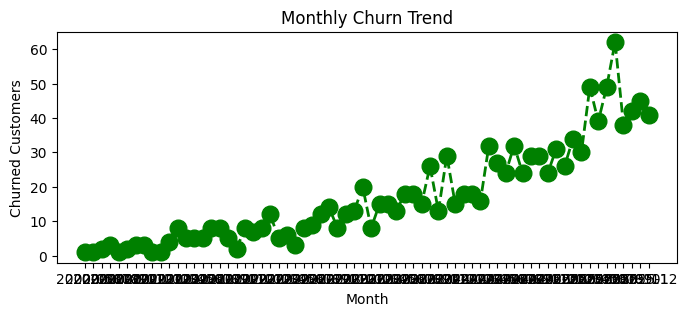

In [54]:
# 4.1 Monthly Churn Trend (Time Series KPI)

df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')

churn_trend = df_visual[df_visual['churn_flag'] == 1].groupby('cancellation_month').size()

plt.figure(figsize=(8,3))
plt.plot(churn_trend.index.astype(str), churn_trend.values,  color='green', marker='o', linestyle='dashed',  linewidth=2, markersize=12)

plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.show()

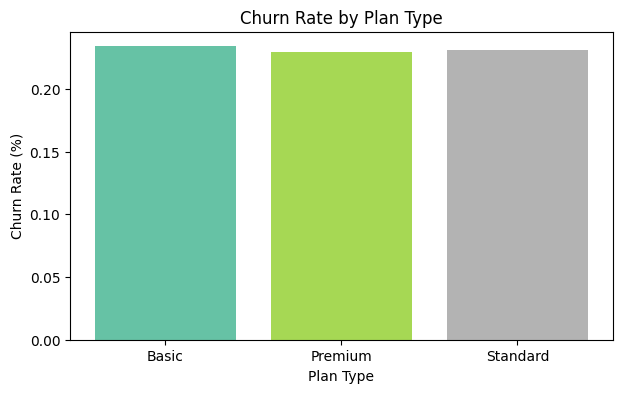

In [55]:
# 4.2 Churn Rate by Plan type
churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean()

# colors = ['yellow', 'purple', 'blue']
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))

plt.figure(figsize=(7,4))
plt.bar(churn_plan.index, churn_plan.values, color = colors)

plt.title('Churn Rate by Plan Type')
plt.xlabel('Plan Type')
plt.ylabel('Churn Rate (%)')
plt.show()

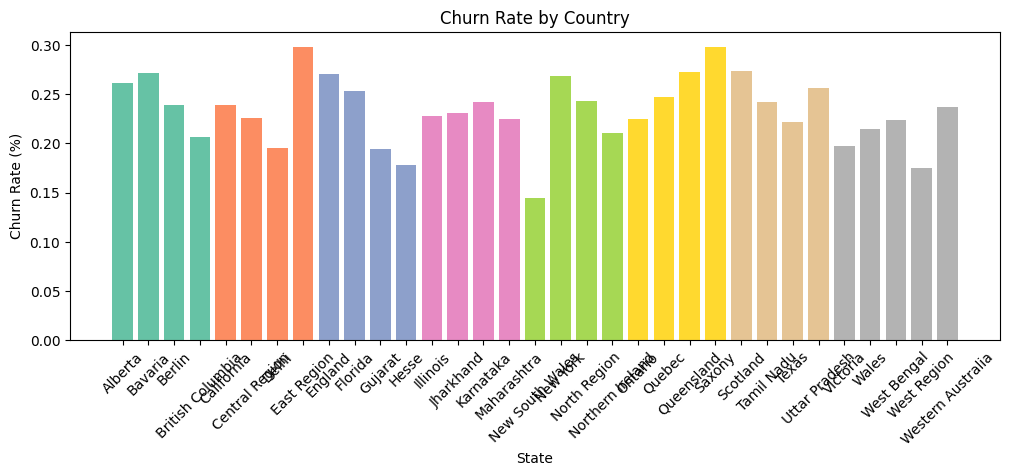

In [56]:
# 4.3 Churn by States
churn_plan = df_visual.groupby('state')['churn_flag'].mean()

# colors = ['yellow', 'purple', 'blue']
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))

plt.figure(figsize=(12,4))
plt.bar(churn_plan.index, churn_plan.values, color = colors)

plt.title('Churn Rate by Country')
plt.xlabel('State')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45)
plt.show()

## Visulaization using Seaborn

In [57]:
# Heatmap (Correlation Matrix)

In [58]:
# encoding - convert str to numeric so that we can find corr between features
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='object')

In [59]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Quarterly,68,0,med,0
1,Basic,Annual,57,0,med,0
2,Standard,Monthly,43,0,low,0
3,Premium,Annual,48,1,low,0
4,Premium,Annual,12,0,low,0


In [60]:
# remove warnings
import warnings
warnings.filterwarnings("ignore")

In [61]:
# incorrect method of encoding - as numbers are not assigned based on priority
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']]

categorial_cols = ['plan_type', 'contract_type', 'churn_risk']

for col in categorial_cols:
    df_encoded[col] = df_encoded[col].astype('category').cat.codes

<Axes: >

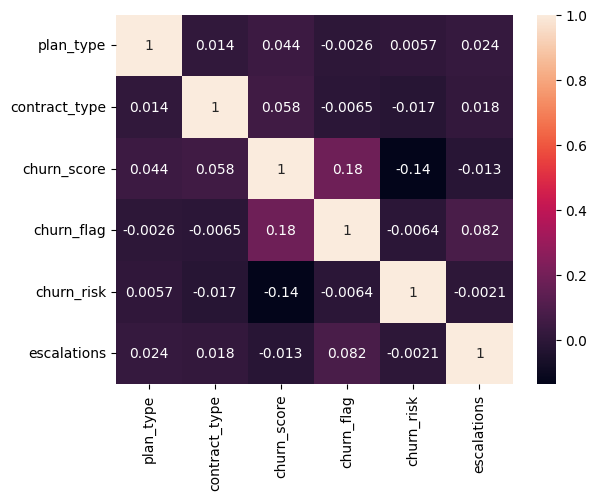

In [62]:
# Heatmap (correlation matrix)

sns.heatmap(df_encoded.corr(), annot=True)

In [63]:
print('plan_type :', df_visual['plan_type'].unique())
print('contract_type :', df_visual['contract_type'].unique())
print('churn_risk :', df_visual['churn_risk'].unique())

plan_type : ['Standard' 'Basic' 'Premium']
contract_type : ['Quarterly' 'Annual' 'Monthly']
churn_risk : ['med' 'low' 'high']


In [64]:
# Correct method of encoding - based on priority
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']]

order_mappings = {
    'plan_type' : ['Basic', 'Standard', 'Premium'],
    'contract_type' : ['Monthly', 'Annual'],
    'churn_risk': ['low', 'med', 'high']
    }

for col, order in order_mappings.items():
    df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'), categories=order, ordered=True).codes

In [65]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Quarterly,68,0,med,0
1,Basic,Annual,57,0,med,0
2,Standard,Monthly,43,0,low,0
3,Premium,Annual,48,1,low,0
4,Premium,Annual,12,0,low,0


In [66]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,1,-1,68,0,1,0
1,0,1,57,0,1,0
2,1,0,43,0,0,0
3,2,1,48,1,0,0
4,2,1,12,0,0,0


<Axes: >

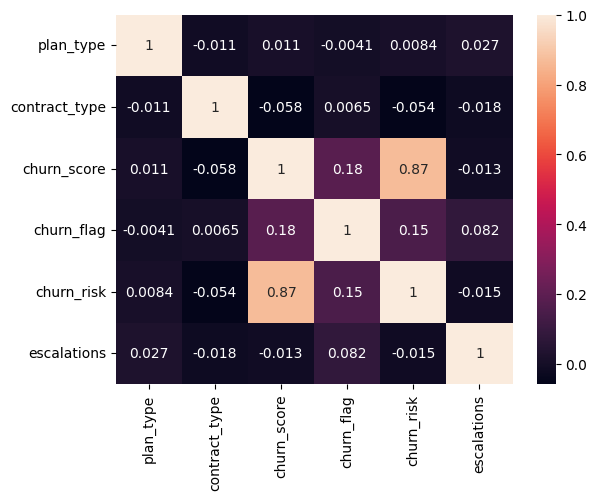

In [67]:
# Heatmap (correlation matrix)
sns.heatmap(df_encoded.corr(), annot=True)

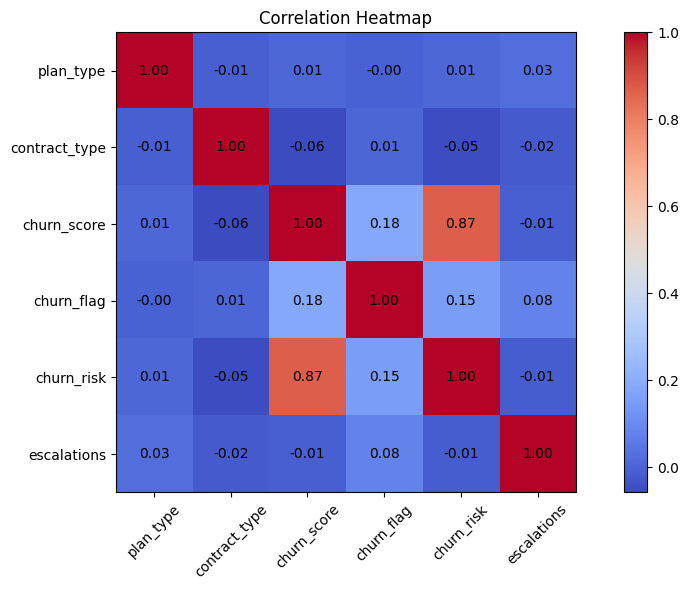

In [68]:
# Heatmap Using Matplotlib - difficult to plot it

corr_matrix = df_encoded.corr() # Correlation matrix

fig, ax = plt.subplots(figsize=(10, 6)) # Create figure

cax = ax.imshow(corr_matrix, cmap='coolwarm') # Heatmap

fig.colorbar(cax) # Add colorbar

# Axis labels
ax.set_xticks(np.arange(len(corr_matrix.columns)))
ax.set_yticks(np.arange(len(corr_matrix.columns)))

ax.set_xticklabels(corr_matrix.columns, rotation=45)
ax.set_yticklabels(corr_matrix.columns)

# Annotate values inside cells
for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        ax.text(
            j,
            i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha='center',
            va='center'
        )

plt.title('Correlation Heatmap') # Title

plt.tight_layout()
plt.show()

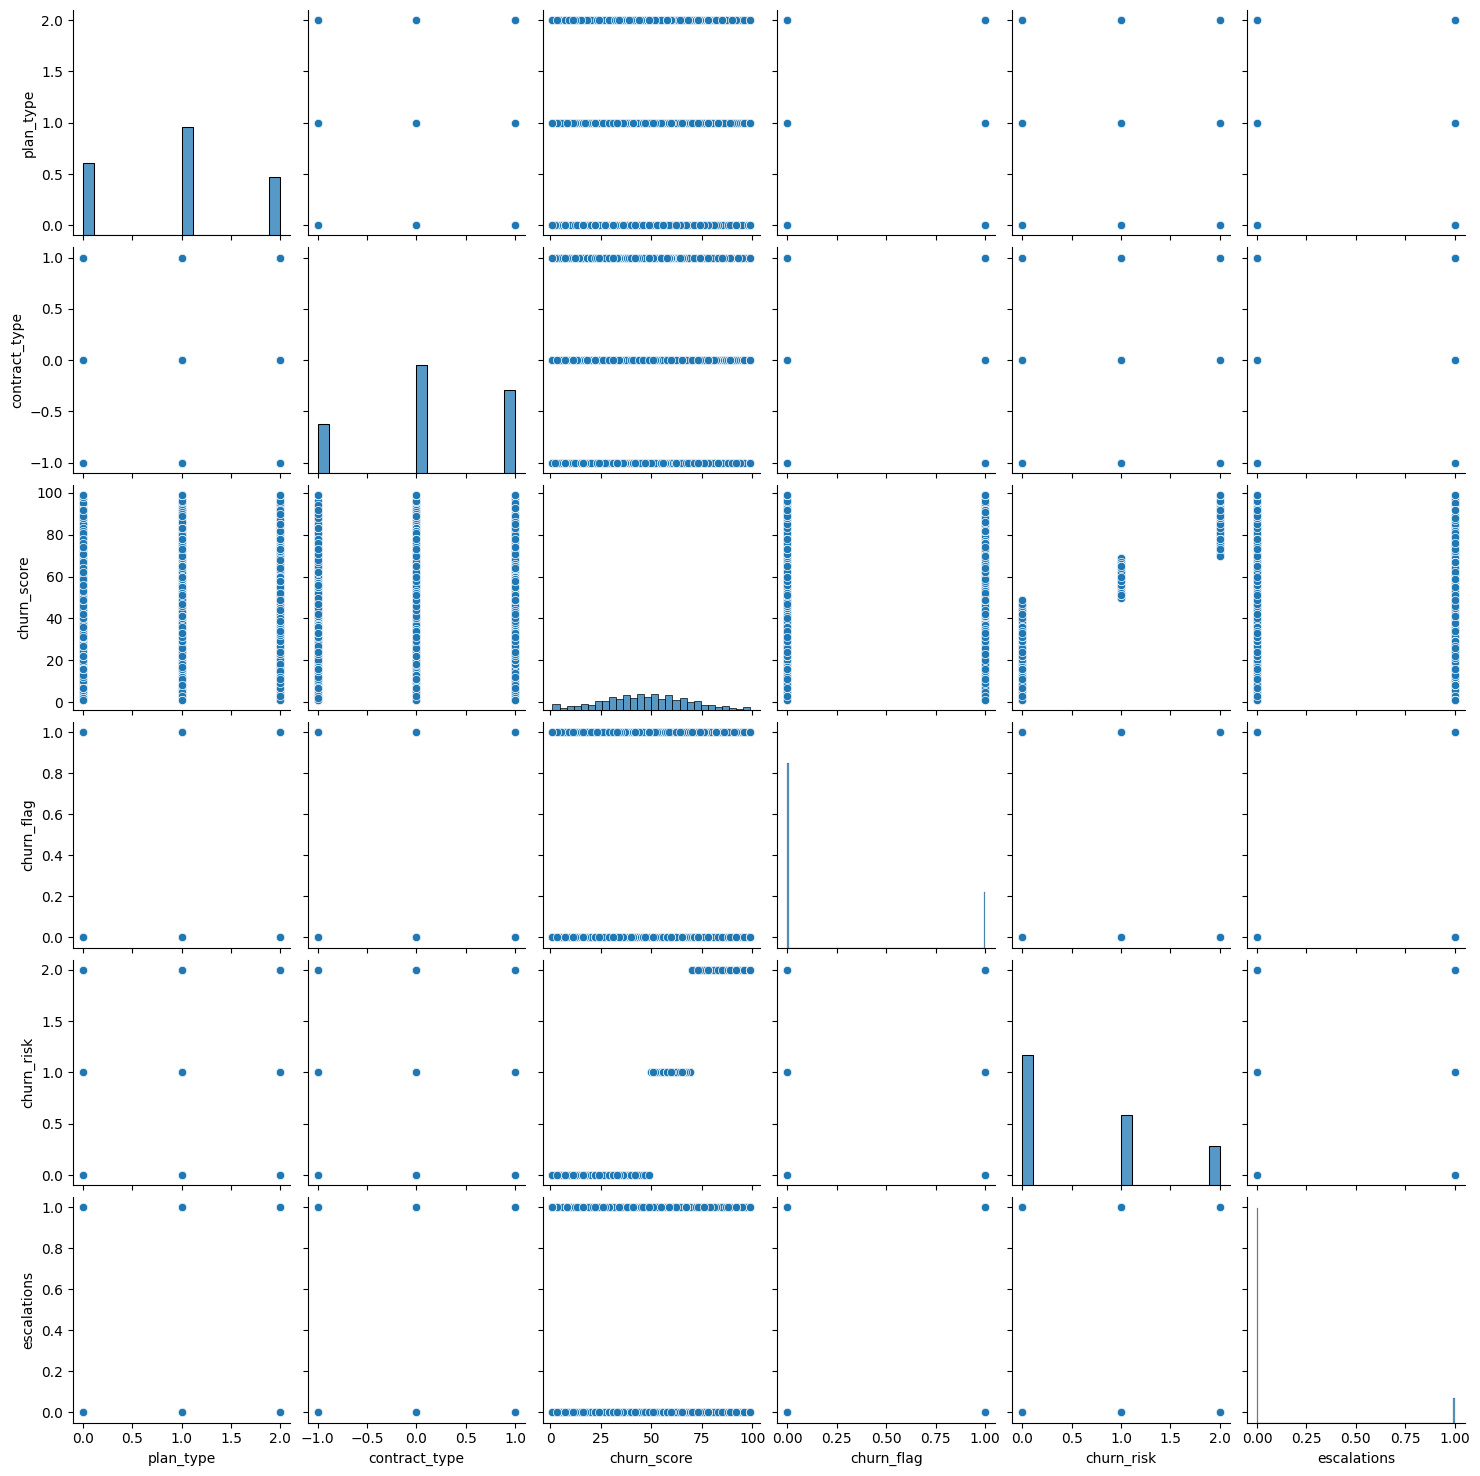

In [69]:
# pairplot - Plot pairwise relationships in a dataset
sns.pairplot(df_encoded)

In [70]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='object')

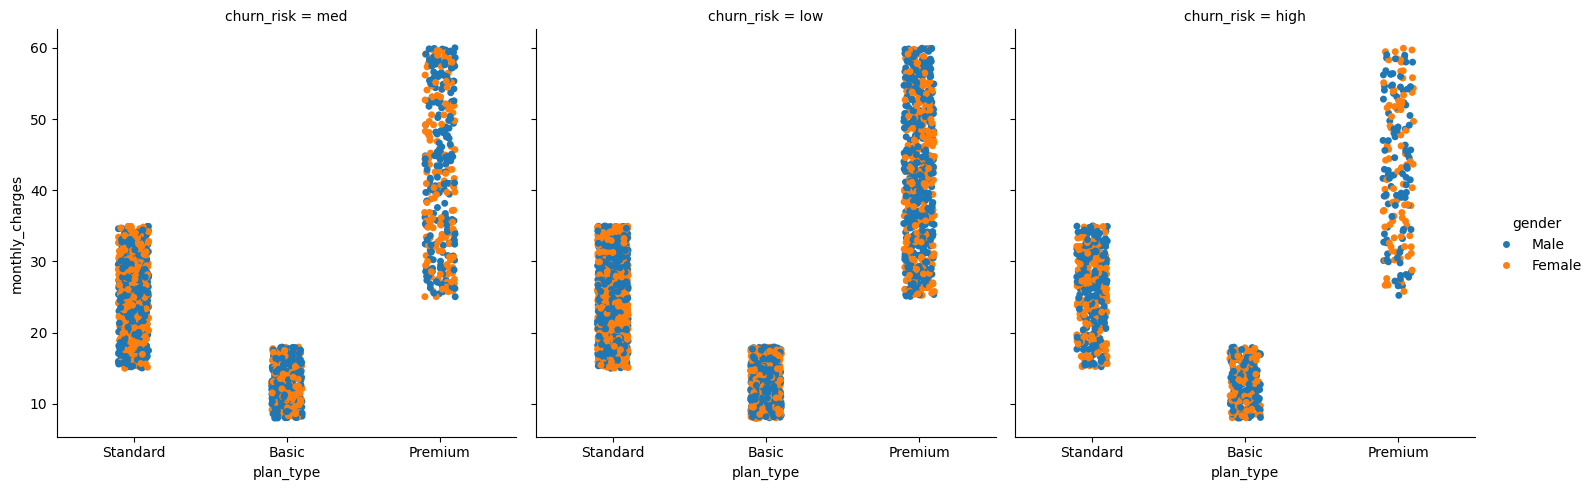

In [71]:
# catplt/Facegrid plot - multi-dim comparison

sns.catplot(data=df_visual,
    x='plan_type',
    y='monthly_charges',
    hue='gender',
    col='churn_risk')

## Pivot table

In [72]:
# Pivot Table

pd.pivot_table(
    df_visual,
    index='plan_type',
    values='churn_flag',
    aggfunc = 'mean'
)

,churn_flag
plan_type,
Basic,0.233860
Premium,0.229184
Standard,0.230939


In [73]:
# pivot table using multiple cols and agg type

pd.pivot_table(
    df_visual,
    index='plan_type',
    values=['monthly_charges', 'customerid', 'churn_flag'],
    aggfunc = {
        'monthly_charges' : 'sum',
        'customerid' : 'nunique',
        'churn_flag' : 'mean'
    }
)

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.233860,1518,19572.96
Premium,0.229184,1213,51752.89
Standard,0.230939,2269,56674.94


## Project Completed :)

In [74]:
# Project Completed Here.